# TEL354 - Minería de Datos

# Taller 1 - Análisis Urbano y Socioeconómico mediante Técnicas de Agrupamiento Avanzadas

Nombre:

# Preparación del Entorno

# Instalación de Dependencias

In [1]:
# Instalar las dependencias necesarias
# pip install geopandas scikit-learn matplotlib seaborn umap-learn hdbscan

# Cargar librerías de trabajo

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
from shapely.geometry import Point, Polygon

# Librerías para clustering y reducción de dimensionalidad
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, SpectralClustering
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
import umap

# Parte 1: Carga y Exploración de Datos

# Geodatos Regionales

In [3]:
# Cargar datos geoespaciales
df = gpd.read_file('division_comunal.shp')
df.head()

,NOM_REG,NOM_PROV,NOM_COM,SHAPE_LENG,DIS_ELEC,CIR_SENA,COD_COMUNA,SHAPE_Le_1,SHAPE_Area,geometry
0,Región de La Araucanía,Malleco,Ercilla,170675.595438,48,14,9204,170675.595706,4.979025e+08,"POLYGON ((190393.220 5794527.366, 190474.419 5..."
1,Región de La Araucanía,Malleco,Lonquimay,346907.195437,49,14,9205,346907.195899,3.932854e+09,"POLYGON ((294265.593 5781748.870, 294327.827 5..."
2,Región de La Araucanía,Malleco,Los Sauces,169844.122286,48,14,9206,169844.122239,8.519730e+08,"POLYGON ((155495.103 5804765.810, 155518.319 5..."
3,Región de La Araucanía,Malleco,Lumaco,227705.219204,48,14,9207,227705.218806,1.112643e+09,"POLYGON ((159561.530 5778741.661, 159745.162 5..."
4,Región de La Araucanía,Malleco,Purén,137030.480474,48,14,9208,137030.480353,4.654760e+08,"POLYGON ((145272.593 5804247.707, 145347.984 5..."


# Geodatos de Santiago

<Figure size 1200x1000 with 0 Axes>

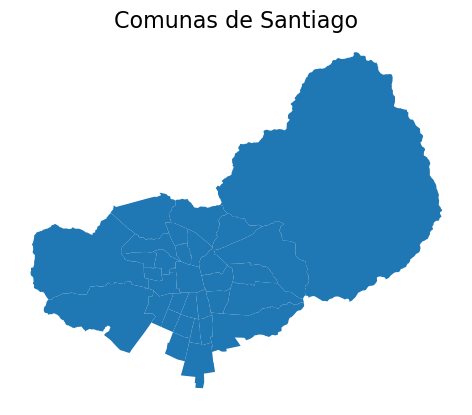

In [4]:
# Filtrar datos de Santiago y convertir a coordenadas WGS84
df_stgo = df[df.NOM_PROV == 'Santiago'].to_crs("EPSG:4326")
df_stgo.head()

# Visualizar mapa base de Santiago
plt.figure(figsize=(12, 10))
df_stgo.plot();
plt.title('Comunas de Santiago', fontsize=16)
plt.axis('off');

# Datos Urbanos de Santiago

Número de registros: 5000
Número de características: 4
Columnas disponibles: ['comuna', 'longitud', 'latitud', 'nse']


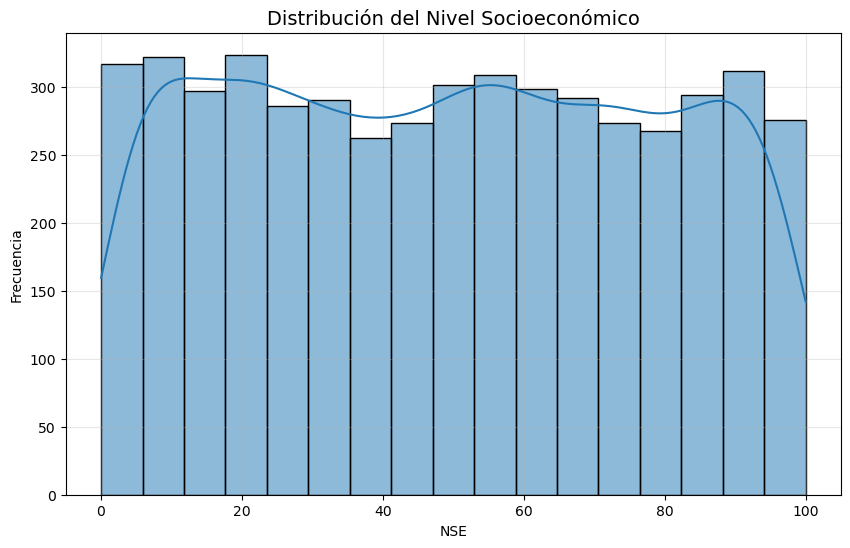

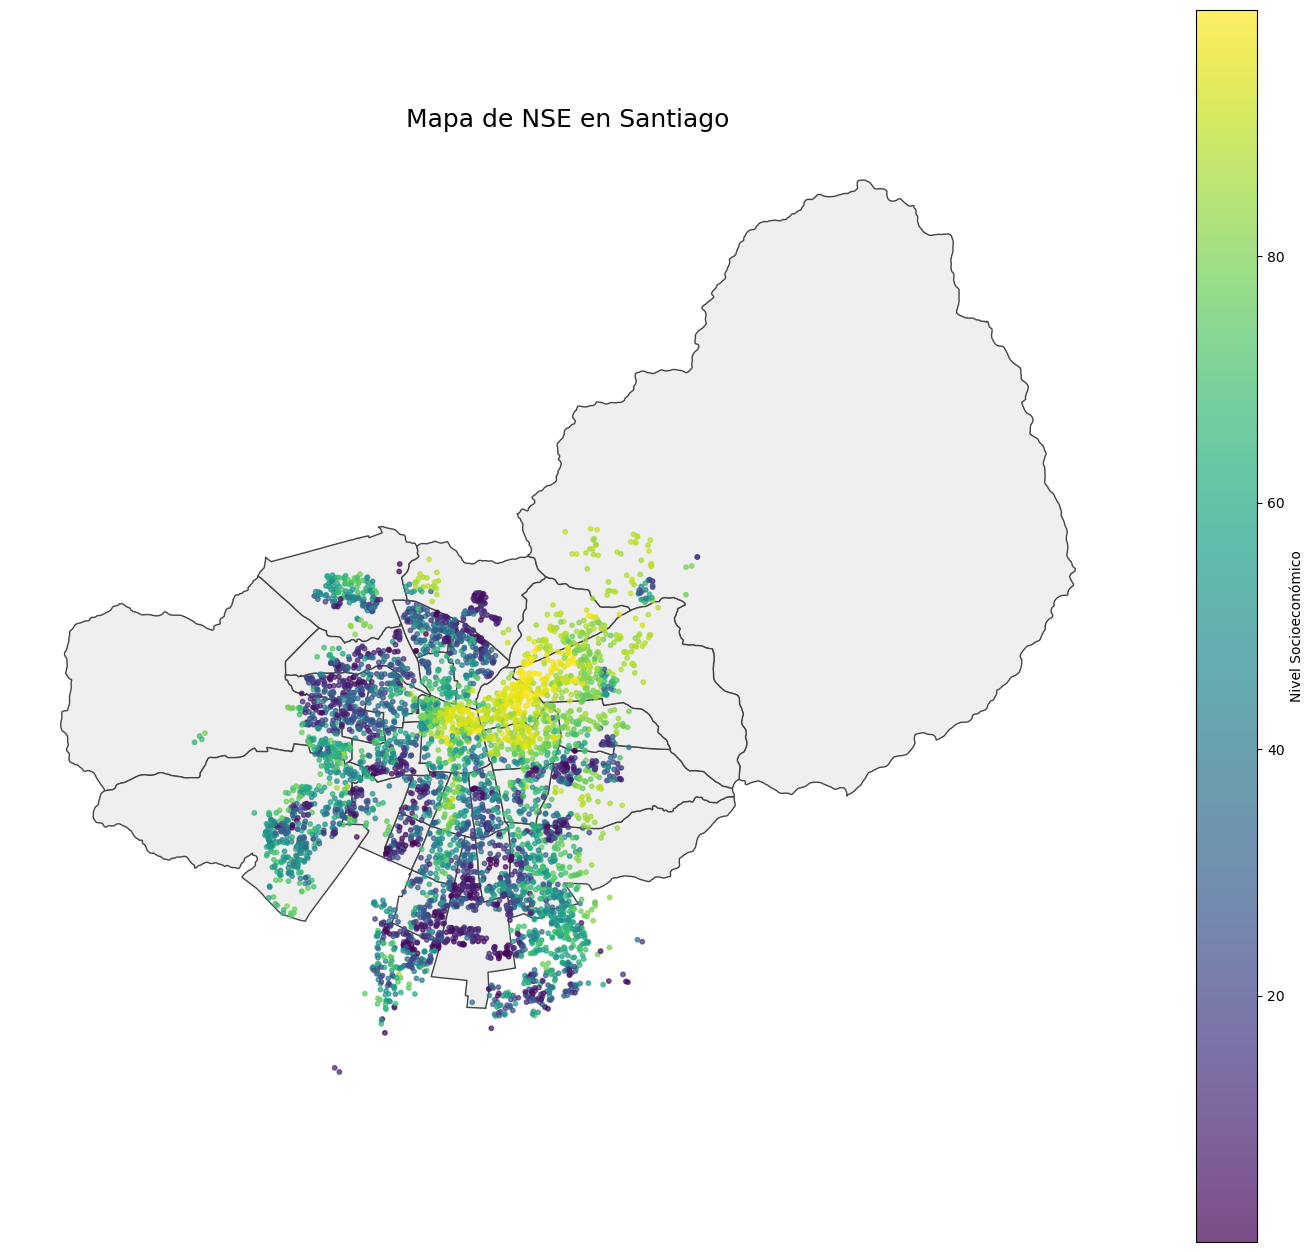

In [5]:
# Cargar datos de barrios
df_barrio = pd.read_csv('barrio.csv')
df_barrio.head()

# Explorar estructura de datos
print(f"Número de registros: {df_barrio.shape[0]}")
print(f"Número de características: {df_barrio.shape[1]}")
print(f"Columnas disponibles: {df_barrio.columns.tolist()}")


# Visualizar distribución de NSE
plt.figure(figsize=(10, 6))
sns.histplot(df_barrio['nse'], kde=True)
plt.title('Distribución del Nivel Socioeconómico', fontsize=14)
plt.xlabel('NSE')
plt.ylabel('Frecuencia')
plt.grid(alpha=0.3)
plt.show()

# Visualizar datos en mapa
ax = df_stgo.plot(figsize=(18, 16), color='#EFEFEF', edgecolor='#444444')
scatter = plt.scatter(df_barrio['longitud'], df_barrio['latitud'], 
                     c=df_barrio['nse'], cmap='viridis', s=10, alpha=0.7)
plt.colorbar(scatter, label='Nivel Socioeconómico')
plt.title('Mapa de NSE en Santiago', fontsize=18)
plt.axis('off');

# Parte 2: Preprocesamiento y Transformación de Datos

# Objetivo

Analizar la estructura socioeconómica y urbana de Santiago mediante técnicas avanzadas de clustering y visualización geoespacial, comparando diferentes enfoques metodológicos y evaluando la calidad de los agrupamientos resultantes. urbanos de Santiago

# Contexto

El nivel socioeconómico (NSE) en Chile tiene siete clases: AB (clase alta), C1a (clase media acomodada), C1b (clase media emergente), C2 (clase media típica), C3 (clase media baja), D (clase media vulnerable) y E (pobres).

# 2.1 Preprocesamiento de Datos

In [6]:
# Estandarizar variables para clustering
features = ['longitud', 'latitud', 'nse']
scaler = StandardScaler()

# Crear un DataFrame agrupado por comuna
comuna_grouped = df_barrio.groupby('comuna').agg({
    'longitud': 'mean',
    'latitud': 'mean',
    'nse': 'mean'
}).reset_index()

# Estandarizar datos agrupados
comuna_scaled = comuna_grouped.copy()
comuna_scaled[features] = scaler.fit_transform(comuna_grouped[features])

# Normalizar nombres de comunas para posterior fusión
comuna_grouped['comuna'] = comuna_grouped['comuna'].str.upper()
df_stgo_norm = df_stgo.copy()
df_stgo_norm['NOM_COM'] = df_stgo_norm['NOM_COM'].str.upper()

# Inspeccionar datos procesados
print("Datos agrupados por comuna:")
comuna_grouped.head()

Datos agrupados por comuna:


,comuna,longitud,latitud,nse
0,CERRILLOS,-70.721842,-33.496831,39.427586
1,CERRO NAVIA,-70.740294,-33.422983,20.584083
2,CONCHALÍ,-70.672558,-33.383486,29.991393
3,EL BOSQUE,-70.671911,-33.565505,26.968053
4,ESTACIÓN CENTRAL,-70.700680,-33.465468,32.830155


# Parte 3: Análisis de Clustering

# 3.1 Determinación del Número Óptimo de Clusters

In [7]:
import warnings
warnings.filterwarnings('ignore')

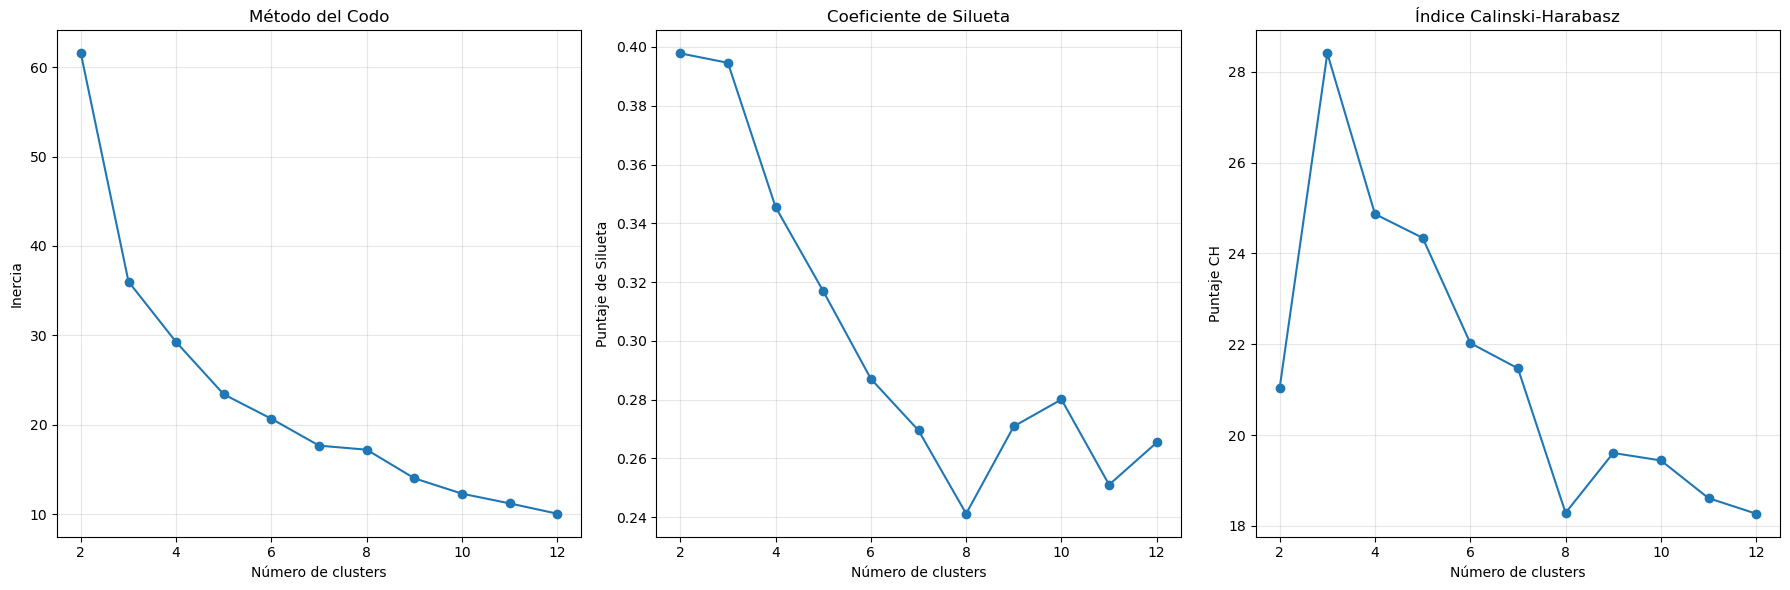

In [8]:
# Función para determinar el número óptimo de clusters usando el método del codo y silueta
def find_optimal_clusters(data, max_clusters=12):
    # Método del codo
    plt.figure(figsize=(18, 6))
    
    # Inercia (WSS - Within-Cluster Sum of Square)
    plt.subplot(1, 3, 1)
    inertias = []
    for k in range(2, max_clusters+1):
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        kmeans.fit(data[features])
        inertias.append(kmeans.inertia_)
    
    plt.plot(range(2, max_clusters+1), inertias, 'o-')
    plt.title('Método del Codo')
    plt.xlabel('Número de clusters')
    plt.ylabel('Inercia')
    plt.grid(alpha=0.3)
    
    # Silueta
    plt.subplot(1, 3, 2)
    silhouettes = []
    for k in range(2, max_clusters+1):
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        labels = kmeans.fit_predict(data[features])
        silhouettes.append(silhouette_score(data[features], labels))
    
    plt.plot(range(2, max_clusters+1), silhouettes, 'o-')
    plt.title('Coeficiente de Silueta')
    plt.xlabel('Número de clusters')
    plt.ylabel('Puntaje de Silueta')
    plt.grid(alpha=0.3)
    
    # Calinski-Harabasz
    plt.subplot(1, 3, 3)
    ch_scores = []
    for k in range(2, max_clusters+1):
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        labels = kmeans.fit_predict(data[features])
        ch_scores.append(calinski_harabasz_score(data[features], labels))
    
    plt.plot(range(2, max_clusters+1), ch_scores, 'o-')
    plt.title('Índice Calinski-Harabasz')
    plt.xlabel('Número de clusters')
    plt.ylabel('Puntaje CH')
    plt.grid(alpha=0.3)
    
    plt.tight_layout()
    plt.show()

# Aplicar a datos agrupados por comuna
find_optimal_clusters(comuna_scaled)

# 3.2 Aplicación de Algoritmos de Clustering

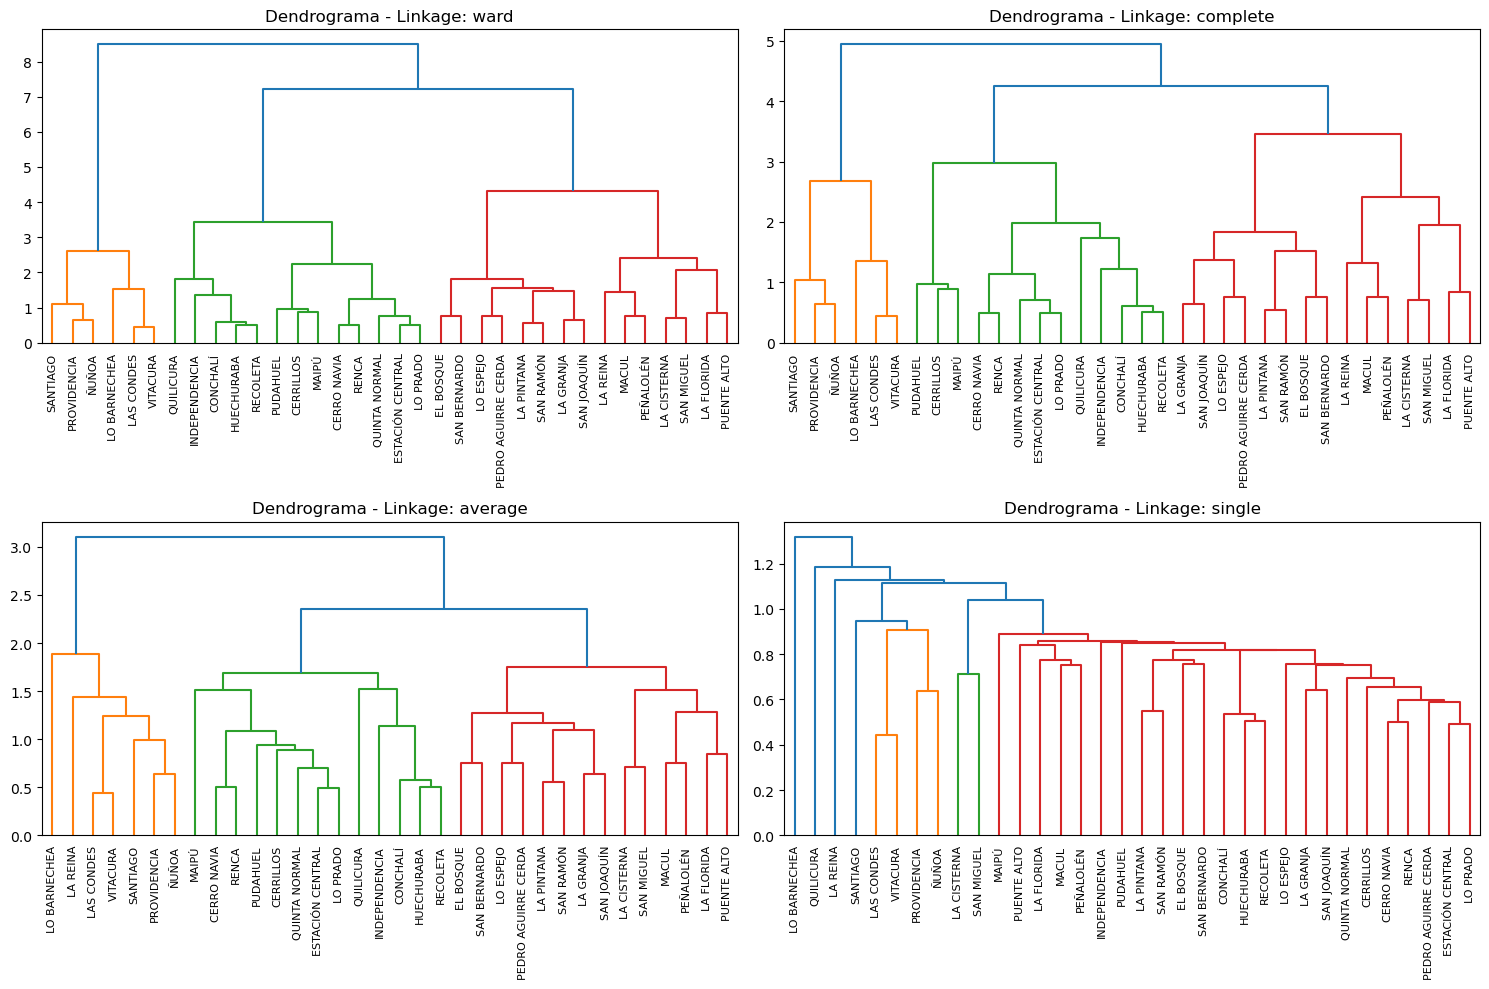

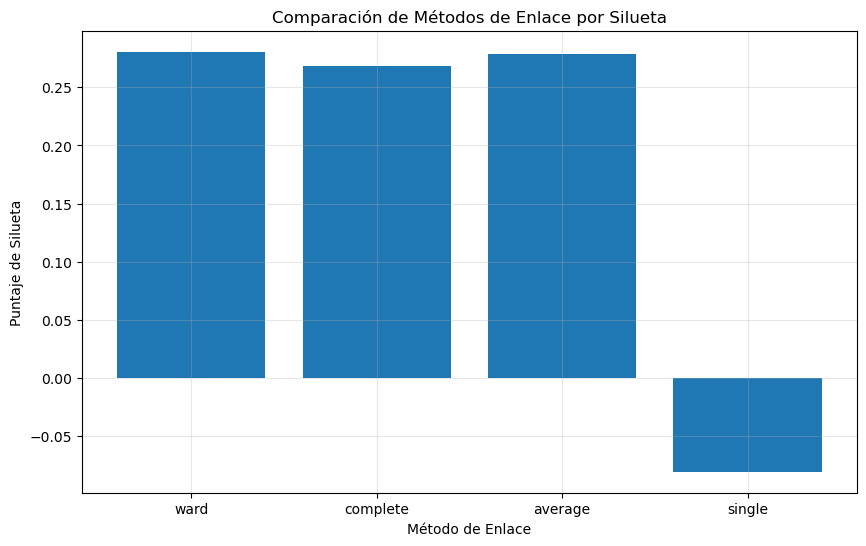

El mejor método de enlace es: ward


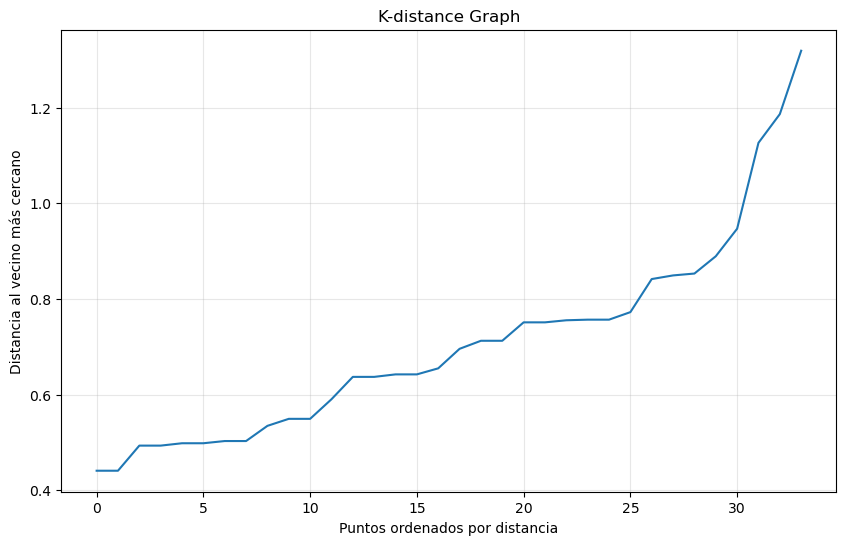

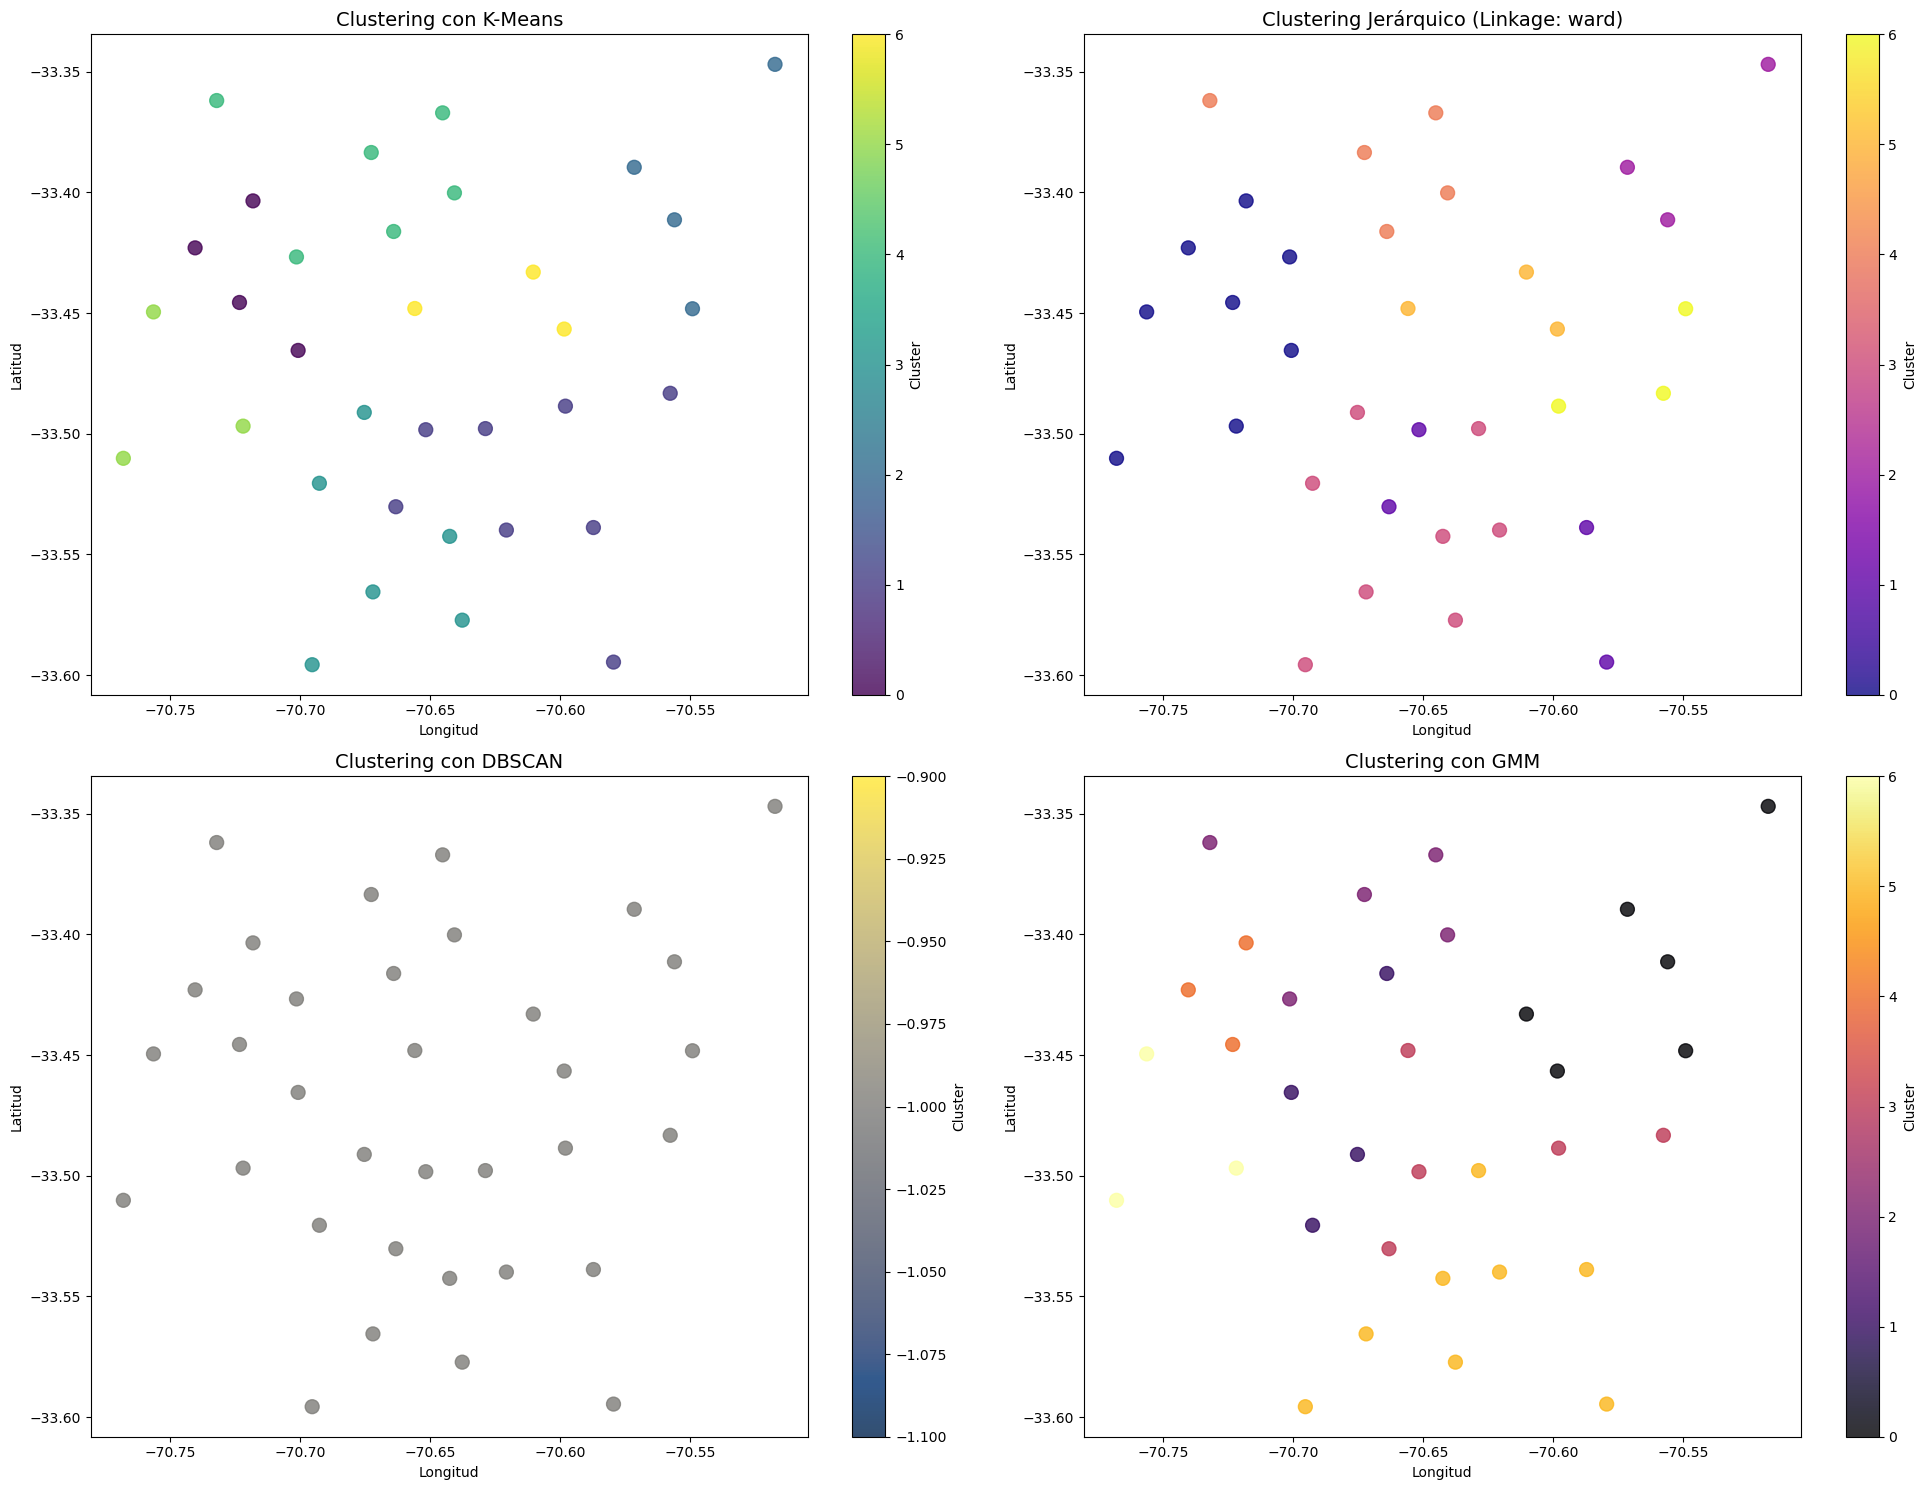

In [9]:
# Aplicar K-Means
k_optimal = 7  # Reemplazar con el valor óptimo según análisis anterior
kmeans = KMeans(n_clusters=k_optimal, random_state=42, n_init=10)
comuna_scaled['kmeans_cluster'] = kmeans.fit_predict(comuna_scaled[features])
comuna_grouped['kmeans_cluster'] = comuna_scaled['kmeans_cluster']

# Aplicar Clustering Jerárquico
linkages = ['ward', 'complete', 'average', 'single']
silhouette_scores = []

plt.figure(figsize=(15, 10))
for i, linkage in enumerate(linkages):
    agg_clustering = AgglomerativeClustering(n_clusters=k_optimal, linkage=linkage)
    labels = agg_clustering.fit_predict(comuna_scaled[features])
    silhouette_scores.append(silhouette_score(comuna_scaled[features], labels))
    
    plt.subplot(2, 2, i+1)
    plt.title(f'Dendrograma - Linkage: {linkage}')
    from scipy.cluster.hierarchy import dendrogram, linkage as scipy_linkage
    
    # Calcular linkage para dendrograma
    Z = scipy_linkage(comuna_scaled[features], method=linkage)
    dendrogram(Z, labels=comuna_scaled['comuna'].values, leaf_rotation=90)
    plt.tight_layout()

plt.figure(figsize=(10, 6))
plt.bar(linkages, silhouette_scores)
plt.title('Comparación de Métodos de Enlace por Silueta')
plt.xlabel('Método de Enlace')
plt.ylabel('Puntaje de Silueta')
plt.grid(alpha=0.3)
plt.show()

# Seleccionar el mejor método de enlace
best_linkage = linkages[np.argmax(silhouette_scores)]
print(f"El mejor método de enlace es: {best_linkage}")

# Aplicar clustering jerárquico con el mejor método
agg_clustering = AgglomerativeClustering(n_clusters=k_optimal, linkage=best_linkage)
comuna_scaled['agg_cluster'] = agg_clustering.fit_predict(comuna_scaled[features])
comuna_grouped['agg_cluster'] = comuna_scaled['agg_cluster']

# Aplicar DBSCAN con optimización de parámetros
from sklearn.neighbors import NearestNeighbors

# Encontrar el valor óptimo de eps
neighbors = NearestNeighbors(n_neighbors=2)
neighbors_fit = neighbors.fit(comuna_scaled[features])
distances, indices = neighbors_fit.kneighbors(comuna_scaled[features])
distances = np.sort(distances[:, 1])

plt.figure(figsize=(10, 6))
plt.plot(distances)
plt.title('K-distance Graph')
plt.xlabel('Puntos ordenados por distancia')
plt.ylabel('Distancia al vecino más cercano')
plt.grid(alpha=0.3)
plt.show()

# Basado en el gráfico, seleccionar un valor de eps
eps_optimal = 0.5  # Reemplazar con el valor apropiado según el gráfico
min_samples = max(k_optimal//2, 2)

dbscan = DBSCAN(eps=eps_optimal, min_samples=min_samples)
comuna_scaled['dbscan_cluster'] = dbscan.fit_predict(comuna_scaled[features])
comuna_grouped['dbscan_cluster'] = comuna_scaled['dbscan_cluster']

# Aplicar un cuarto algoritmo: Gaussian Mixture Models (GMM)
gmm = GaussianMixture(n_components=k_optimal, random_state=42)
comuna_scaled['gmm_cluster'] = gmm.fit_predict(comuna_scaled[features])
comuna_grouped['gmm_cluster'] = comuna_scaled['gmm_cluster']

# Comparación de resultados entre algoritmos
plt.figure(figsize=(20, 15))

# KMeans
plt.subplot(2, 2, 1)
plt.scatter(comuna_grouped['longitud'], comuna_grouped['latitud'], 
           c=comuna_grouped['kmeans_cluster'], cmap='viridis', s=100, alpha=0.8)
plt.title('Clustering con K-Means', fontsize=14)
plt.colorbar(label='Cluster')
plt.xlabel('Longitud')
plt.ylabel('Latitud')

# Agglomerative
plt.subplot(2, 2, 2)
plt.scatter(comuna_grouped['longitud'], comuna_grouped['latitud'], 
           c=comuna_grouped['agg_cluster'], cmap='plasma', s=100, alpha=0.8)
plt.title(f'Clustering Jerárquico (Linkage: {best_linkage})', fontsize=14)
plt.colorbar(label='Cluster')
plt.xlabel('Longitud')
plt.ylabel('Latitud')

# DBSCAN
plt.subplot(2, 2, 3)
plt.scatter(comuna_grouped['longitud'], comuna_grouped['latitud'], 
           c=comuna_grouped['dbscan_cluster'], cmap='cividis', s=100, alpha=0.8)
plt.title('Clustering con DBSCAN', fontsize=14)
plt.colorbar(label='Cluster')
plt.xlabel('Longitud')
plt.ylabel('Latitud')

# GMM
plt.subplot(2, 2, 4)
plt.scatter(comuna_grouped['longitud'], comuna_grouped['latitud'], 
           c=comuna_grouped['gmm_cluster'], cmap='inferno', s=100, alpha=0.8)
plt.title('Clustering con GMM', fontsize=14)
plt.colorbar(label='Cluster')
plt.xlabel('Longitud')
plt.ylabel('Latitud')

plt.tight_layout()
plt.show()

# 3.3 Fusión con Datos Geoespaciales y Visualización en Mapa

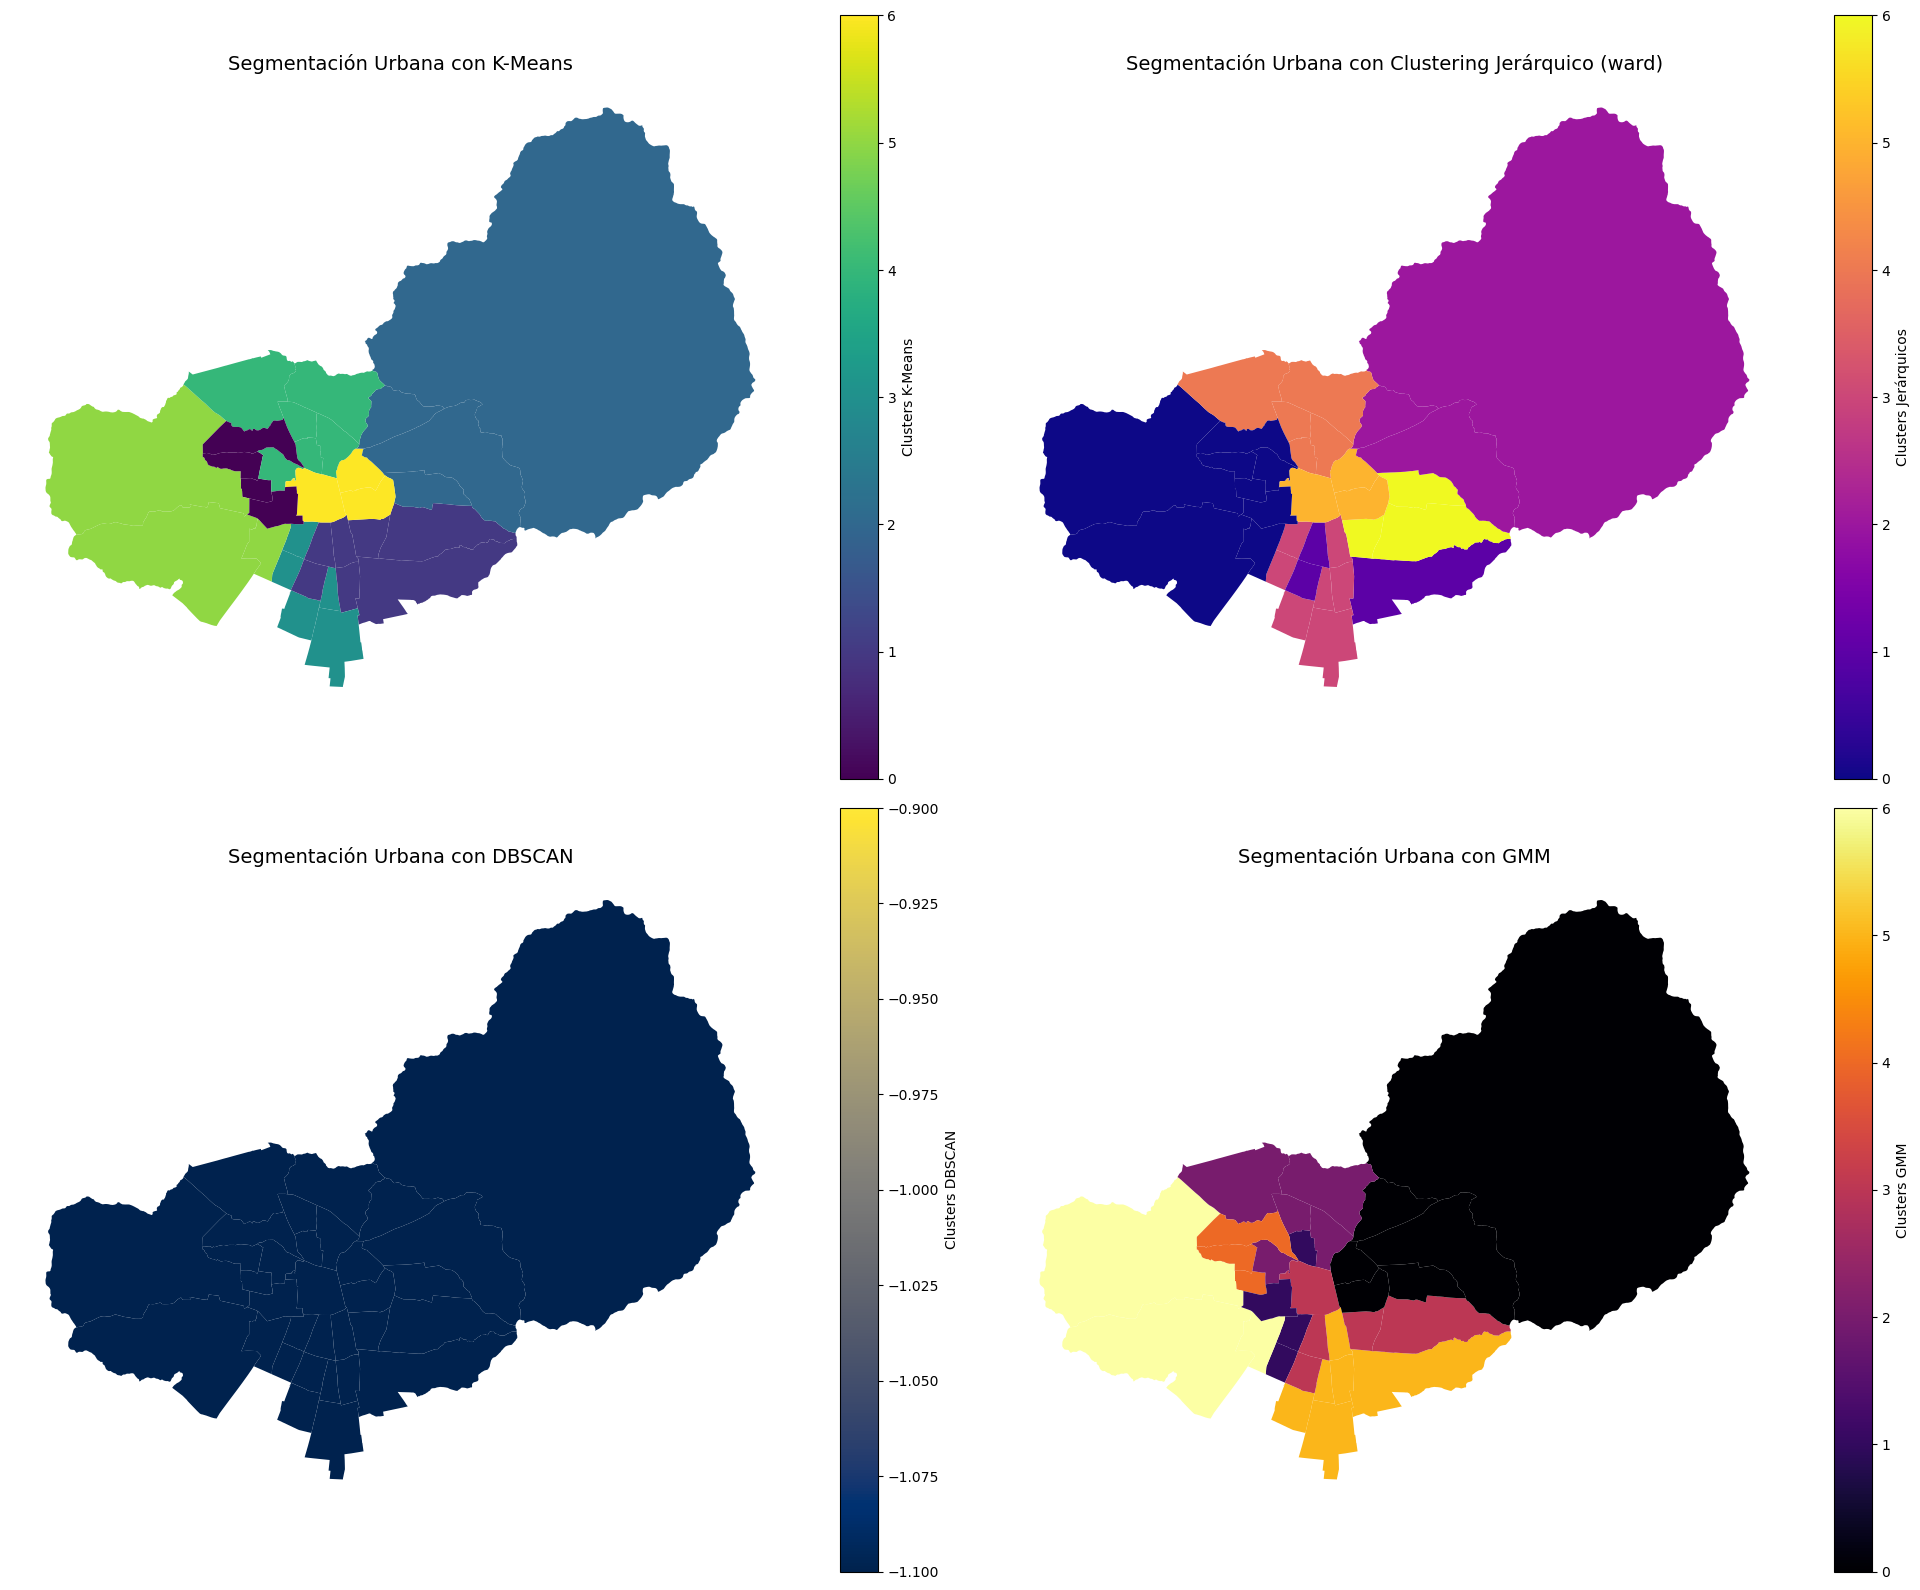

In [10]:
# Preparar datos para fusionar
comuna_geo = comuna_grouped.copy()

# Fusionar con datos geoespaciales
# Asegurarse que los nombres de comunas coincidan
df_stgo_merged = df_stgo_norm.merge(comuna_geo, left_on='NOM_COM', right_on='comuna', how='left')

# Visualizar resultados en mapas para cada algoritmo
fig, axes = plt.subplots(2, 2, figsize=(20, 16))
axes = axes.flatten()

# K-Means en mapa
df_stgo_merged.plot(column='kmeans_cluster', cmap='viridis', legend=True, 
                   legend_kwds={'label': "Clusters K-Means"}, ax=axes[0])
axes[0].set_title('Segmentación Urbana con K-Means', fontsize=14)

# Clustering Jerárquico en mapa
df_stgo_merged.plot(column='agg_cluster', cmap='plasma', legend=True, 
                   legend_kwds={'label': "Clusters Jerárquicos"}, ax=axes[1])
axes[1].set_title(f'Segmentación Urbana con Clustering Jerárquico ({best_linkage})', fontsize=14)

# DBSCAN en mapa
df_stgo_merged.plot(column='dbscan_cluster', cmap='cividis', legend=True, 
                   legend_kwds={'label': "Clusters DBSCAN"}, ax=axes[2])
axes[2].set_title('Segmentación Urbana con DBSCAN', fontsize=14)

# GMM en mapa
df_stgo_merged.plot(column='gmm_cluster', cmap='inferno', legend=True, 
                   legend_kwds={'label': "Clusters GMM"}, ax=axes[3])
axes[3].set_title('Segmentación Urbana con GMM', fontsize=14)

for ax in axes:
    ax.set_axis_off()

plt.tight_layout()
plt.savefig('segmentacion_urbana_santiago.png', dpi=300, bbox_inches='tight')
plt.show()

# Parte 4: Análisis de NSE por Cluster

# 4.1 Caracterización de Clusters

Estadísticas de NSE por cluster (K-Means):
                      nse                                       
                     mean        std        min        max count
kmeans_cluster                                                  
0               26.877959   5.334465  20.584083  32.830155     4
1               43.730508   9.475864  30.916561  59.559851     8
2               77.847663  11.597810  64.713062  89.295055     4
3               23.099159   9.378475  12.644989  37.189347     6
4               40.833573   9.690756  29.991393  53.602546     6
5               44.057093   4.977069  39.427586  49.320908     3
6               83.616084   7.807411  76.952807  92.206642     3


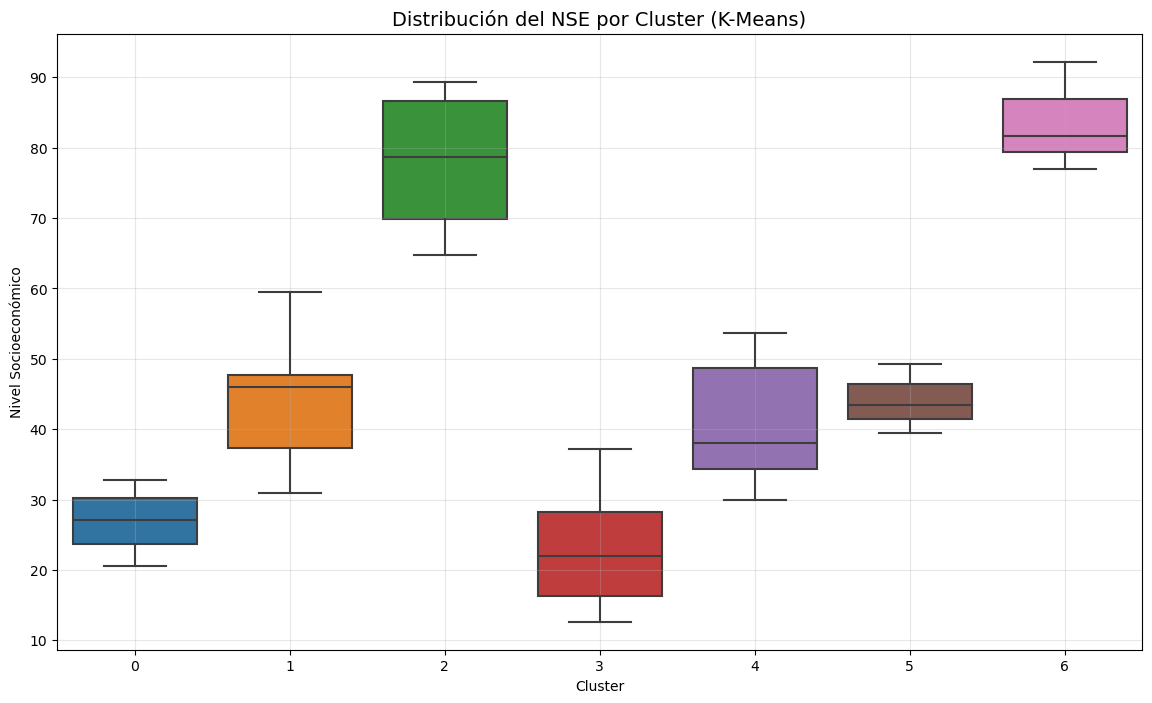

<Figure size 1200x1000 with 0 Axes>

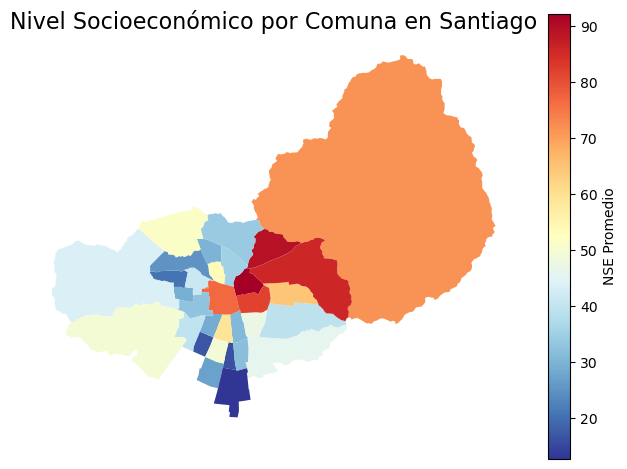

In [11]:
# Analizar características de cada cluster para K-Means
cluster_stats = comuna_grouped.groupby('kmeans_cluster').agg({
    'nse': ['mean', 'std', 'min', 'max', 'count']
})

print("Estadísticas de NSE por cluster (K-Means):")
print(cluster_stats)

# Visualizar distribución de NSE por cluster
plt.figure(figsize=(14, 8))
sns.boxplot(x='kmeans_cluster', y='nse', data=comuna_grouped)
plt.title('Distribución del NSE por Cluster (K-Means)', fontsize=14)
plt.xlabel('Cluster')
plt.ylabel('Nivel Socioeconómico')
plt.grid(alpha=0.3)
plt.show()

# Crear mapa de calor de NSE promedio por cluster
plt.figure(figsize=(12, 10))
df_stgo_merged.plot(column='nse', cmap='RdYlBu_r', legend=True, 
                   legend_kwds={'label': "NSE Promedio"})
plt.title('Nivel Socioeconómico por Comuna en Santiago', fontsize=16)
plt.axis('off')
plt.tight_layout()
plt.show()

# Parte 5: Reducción de Dimensionalidad y Visualización Avanzada

# 5.1 Análisis de Componentes Principales (PCA)

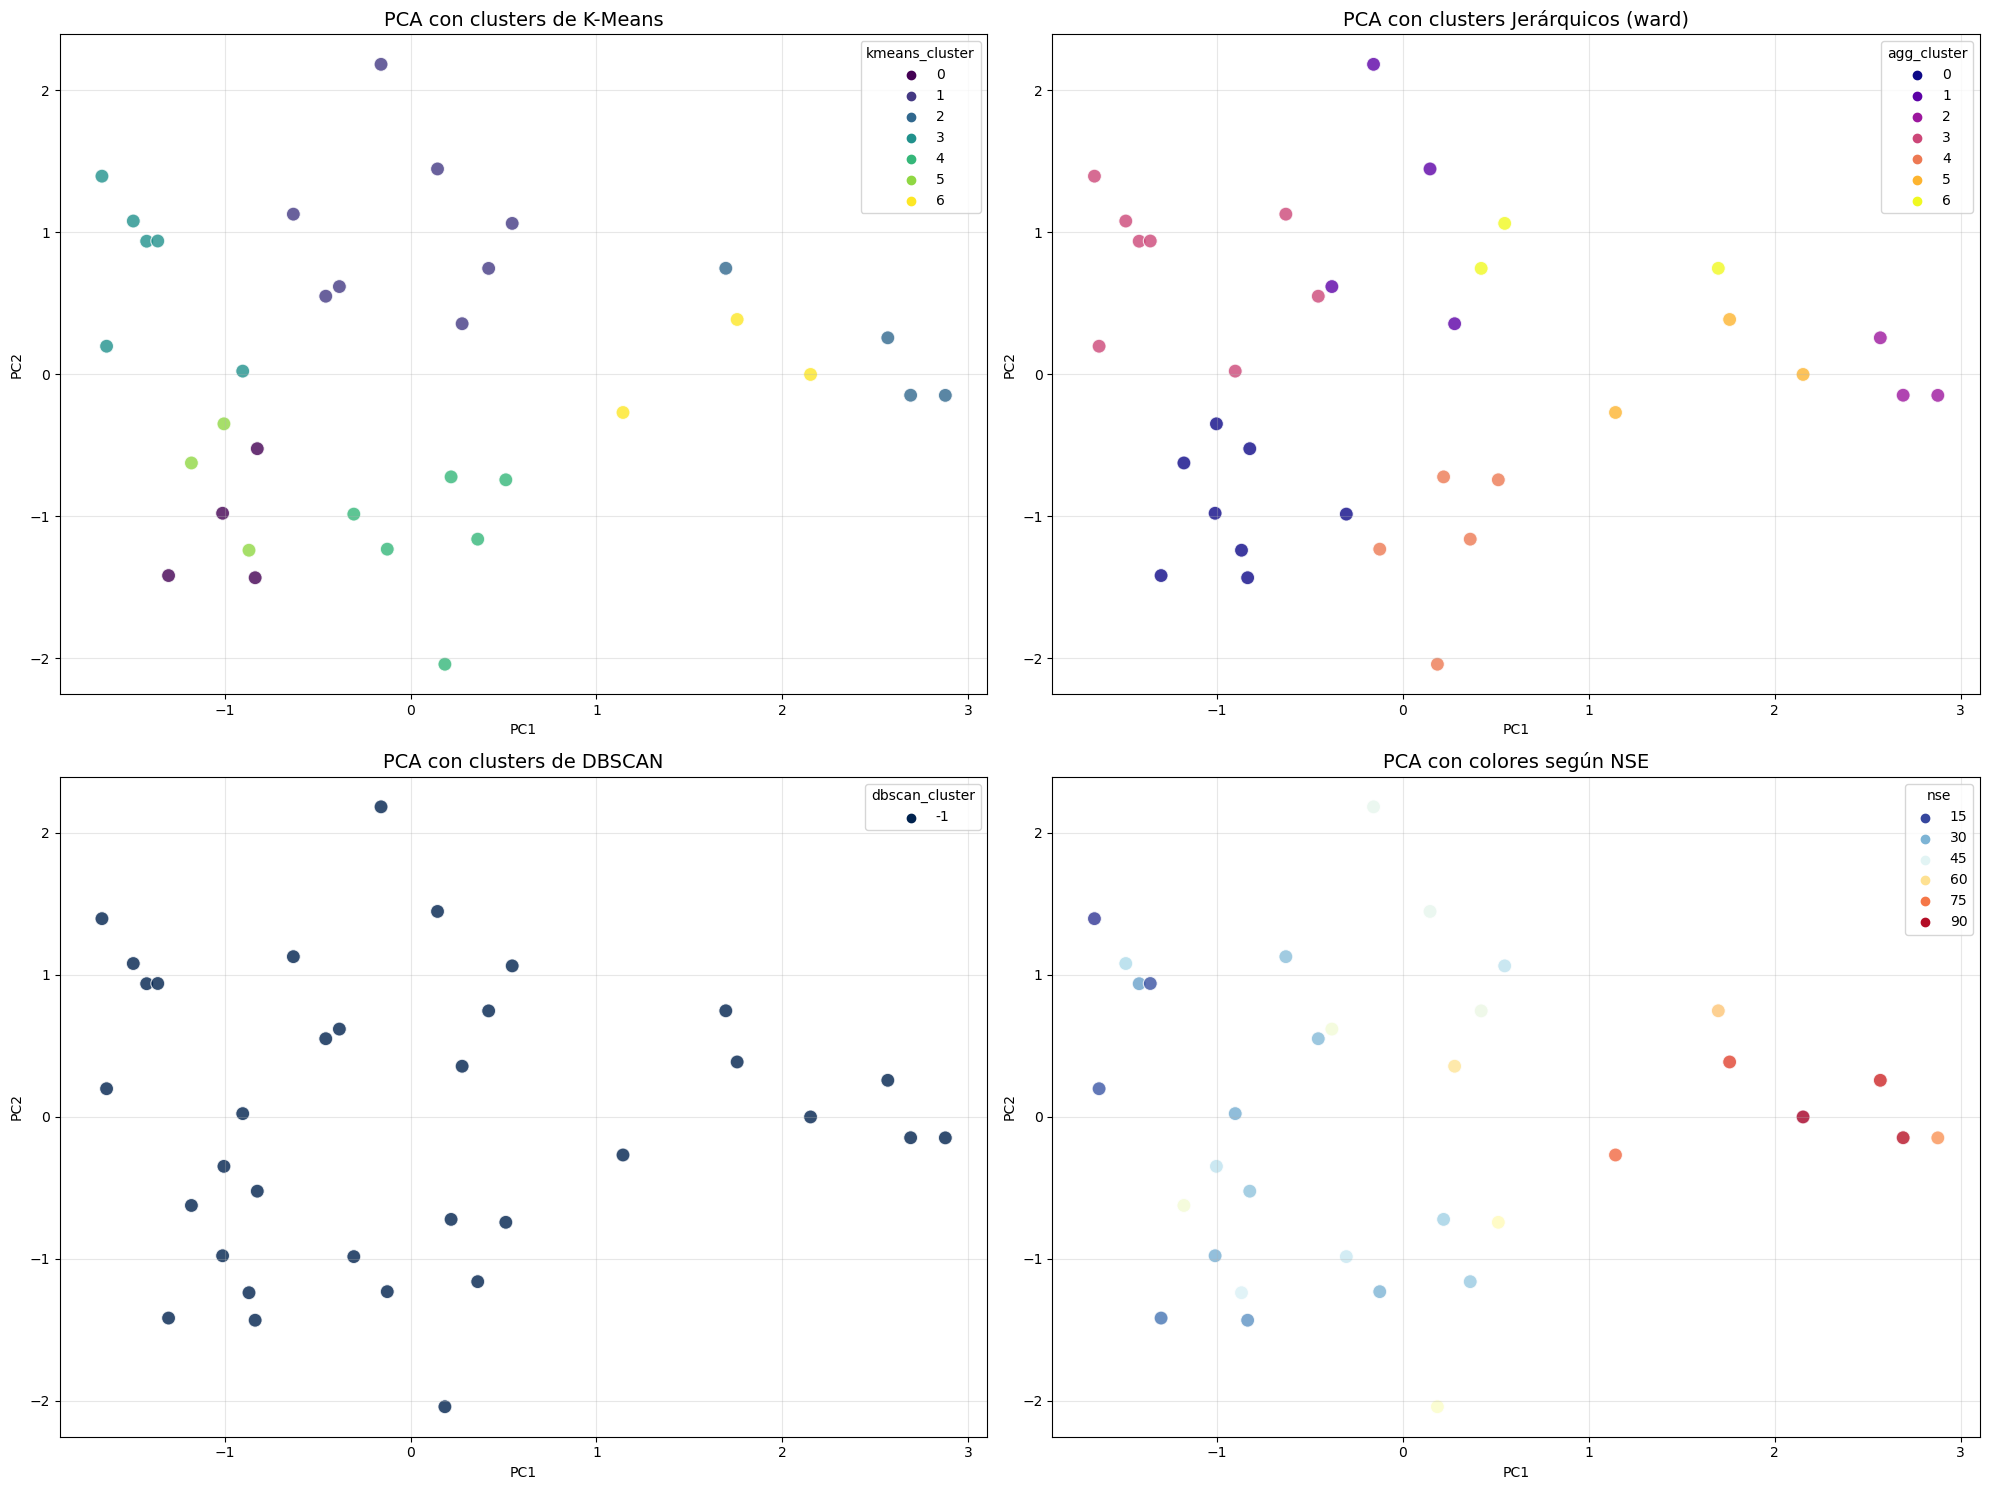

Varianza explicada por PC1: 0.5441
Varianza explicada por PC2: 0.3222
Varianza acumulada: 0.8663


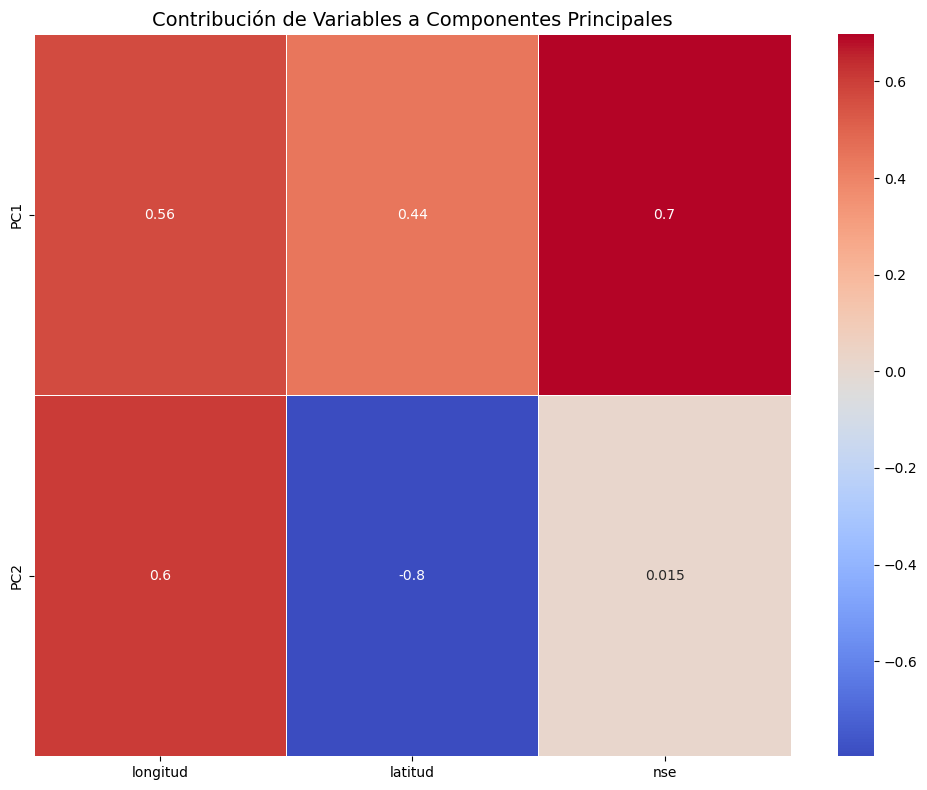

In [12]:
# Aplicar PCA a los datos originales
pca = PCA(n_components=2)
comuna_pca = pca.fit_transform(comuna_scaled[features])

# Crear DataFrame con resultados de PCA
pca_df = pd.DataFrame({
    'comuna': comuna_scaled['comuna'],
    'PC1': comuna_pca[:, 0],
    'PC2': comuna_pca[:, 1],
    'kmeans_cluster': comuna_scaled['kmeans_cluster'],
    'agg_cluster': comuna_scaled['agg_cluster'],
    'dbscan_cluster': comuna_scaled['dbscan_cluster'],
    'gmm_cluster': comuna_scaled['gmm_cluster'],
    'nse': comuna_grouped['nse']
})

# Visualizar resultados de PCA con colores según clustering
plt.figure(figsize=(20, 15))

plt.subplot(2, 2, 1)
sns.scatterplot(x='PC1', y='PC2', hue='kmeans_cluster', palette='viridis', 
               data=pca_df, s=100, alpha=0.8)
plt.title('PCA con clusters de K-Means', fontsize=14)
plt.grid(alpha=0.3)

plt.subplot(2, 2, 2)
sns.scatterplot(x='PC1', y='PC2', hue='agg_cluster', palette='plasma', 
               data=pca_df, s=100, alpha=0.8)
plt.title(f'PCA con clusters Jerárquicos ({best_linkage})', fontsize=14)
plt.grid(alpha=0.3)

plt.subplot(2, 2, 3)
sns.scatterplot(x='PC1', y='PC2', hue='dbscan_cluster', palette='cividis', 
               data=pca_df, s=100, alpha=0.8)
plt.title('PCA con clusters de DBSCAN', fontsize=14)
plt.grid(alpha=0.3)

plt.subplot(2, 2, 4)
sns.scatterplot(x='PC1', y='PC2', hue='nse', palette='RdYlBu_r', 
               data=pca_df, s=100, alpha=0.8)
plt.title('PCA con colores según NSE', fontsize=14)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Analizar la varianza explicada por cada componente
explained_variance = pca.explained_variance_ratio_
print(f"Varianza explicada por PC1: {explained_variance[0]:.4f}")
print(f"Varianza explicada por PC2: {explained_variance[1]:.4f}")
print(f"Varianza acumulada: {sum(explained_variance):.4f}")

# Visualizar importancia de variables en componentes principales
components = pd.DataFrame(pca.components_, columns=features, index=['PC1', 'PC2'])
plt.figure(figsize=(10, 8))
sns.heatmap(components, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Contribución de Variables a Componentes Principales', fontsize=14)
plt.tight_layout()
plt.show()

# 5.2 Aplicación de UMAP para Visualización No Lineal

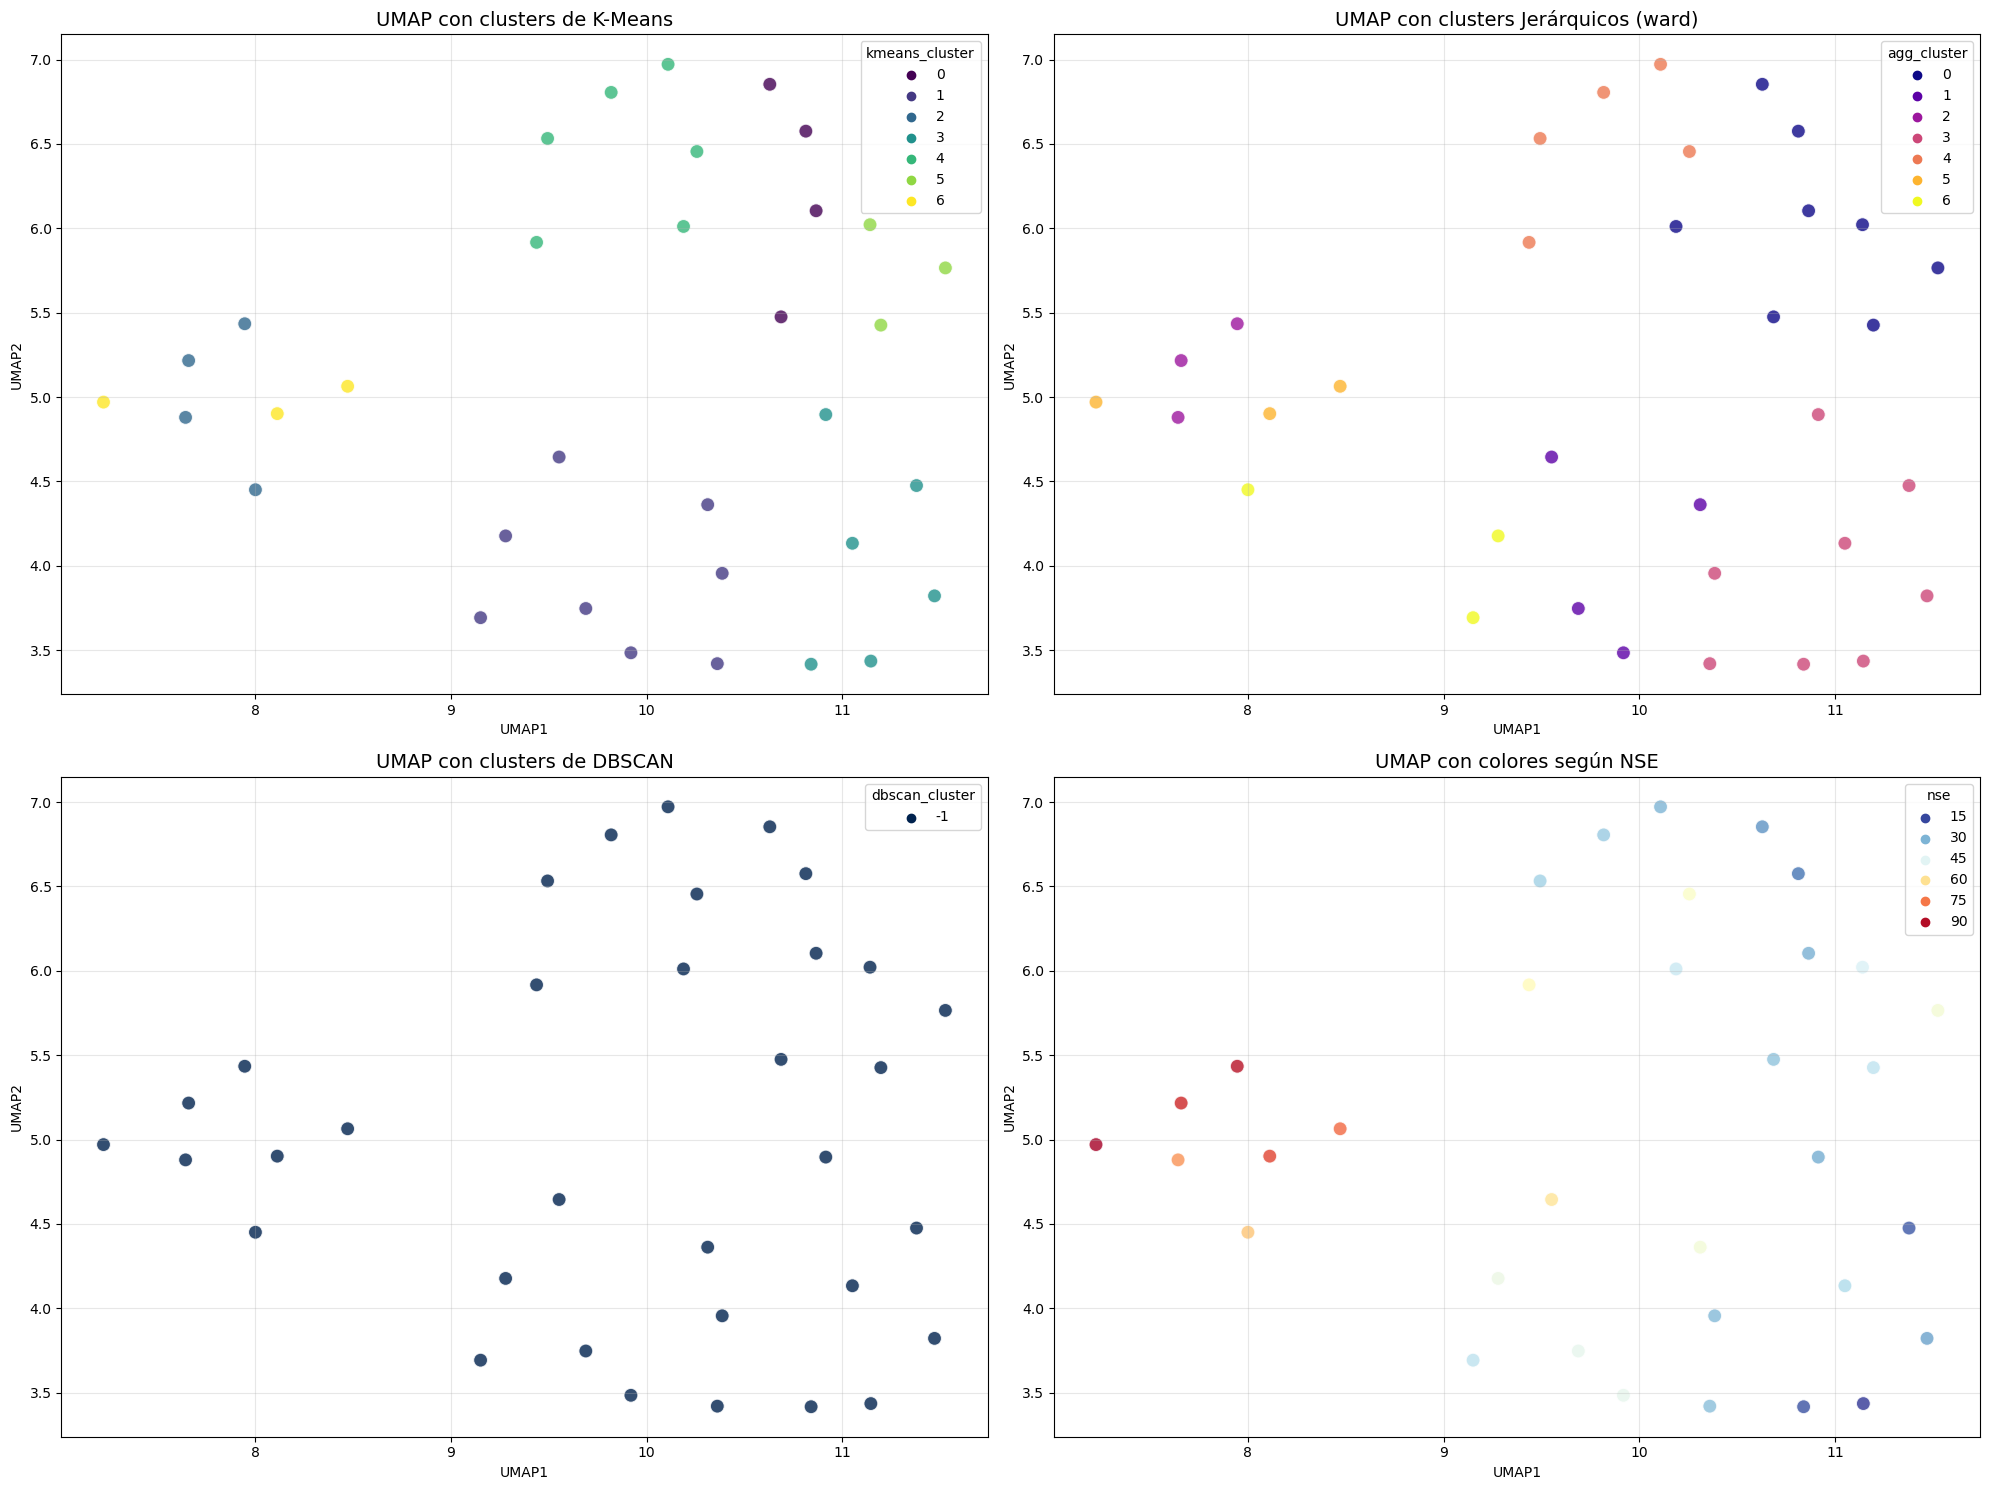

In [13]:
# Aplicar UMAP para visualización no lineal
reducer = umap.UMAP(random_state=42)
embedding = reducer.fit_transform(comuna_scaled[features])

# Crear DataFrame con resultados
umap_df = pd.DataFrame({
    'comuna': comuna_scaled['comuna'],
    'UMAP1': embedding[:, 0],
    'UMAP2': embedding[:, 1],
    'kmeans_cluster': comuna_scaled['kmeans_cluster'],
    'agg_cluster': comuna_scaled['agg_cluster'],
    'dbscan_cluster': comuna_scaled['dbscan_cluster'],
    'gmm_cluster': comuna_scaled['gmm_cluster'],
    'nse': comuna_grouped['nse']
})

# Visualizar resultados de UMAP con colores según clustering
plt.figure(figsize=(20, 15))

plt.subplot(2, 2, 1)
sns.scatterplot(x='UMAP1', y='UMAP2', hue='kmeans_cluster', palette='viridis', 
               data=umap_df, s=100, alpha=0.8)
plt.title('UMAP con clusters de K-Means', fontsize=14)
plt.grid(alpha=0.3)

plt.subplot(2, 2, 2)
sns.scatterplot(x='UMAP1', y='UMAP2', hue='agg_cluster', palette='plasma', 
               data=umap_df, s=100, alpha=0.8)
plt.title(f'UMAP con clusters Jerárquicos ({best_linkage})', fontsize=14)
plt.grid(alpha=0.3)

plt.subplot(2, 2, 3)
sns.scatterplot(x='UMAP1', y='UMAP2', hue='dbscan_cluster', palette='cividis', 
               data=umap_df, s=100, alpha=0.8)
plt.title('UMAP con clusters de DBSCAN', fontsize=14)
plt.grid(alpha=0.3)

plt.subplot(2, 2, 4)
sns.scatterplot(x='UMAP1', y='UMAP2', hue='nse', palette='RdYlBu_r', 
               data=umap_df, s=100, alpha=0.8)
plt.title('UMAP con colores según NSE', fontsize=14)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Parte 6: Análisis Geoespacial Integrado con Riqueza Urbana

# 6.1 Análisis de Hot Spots de Riqueza

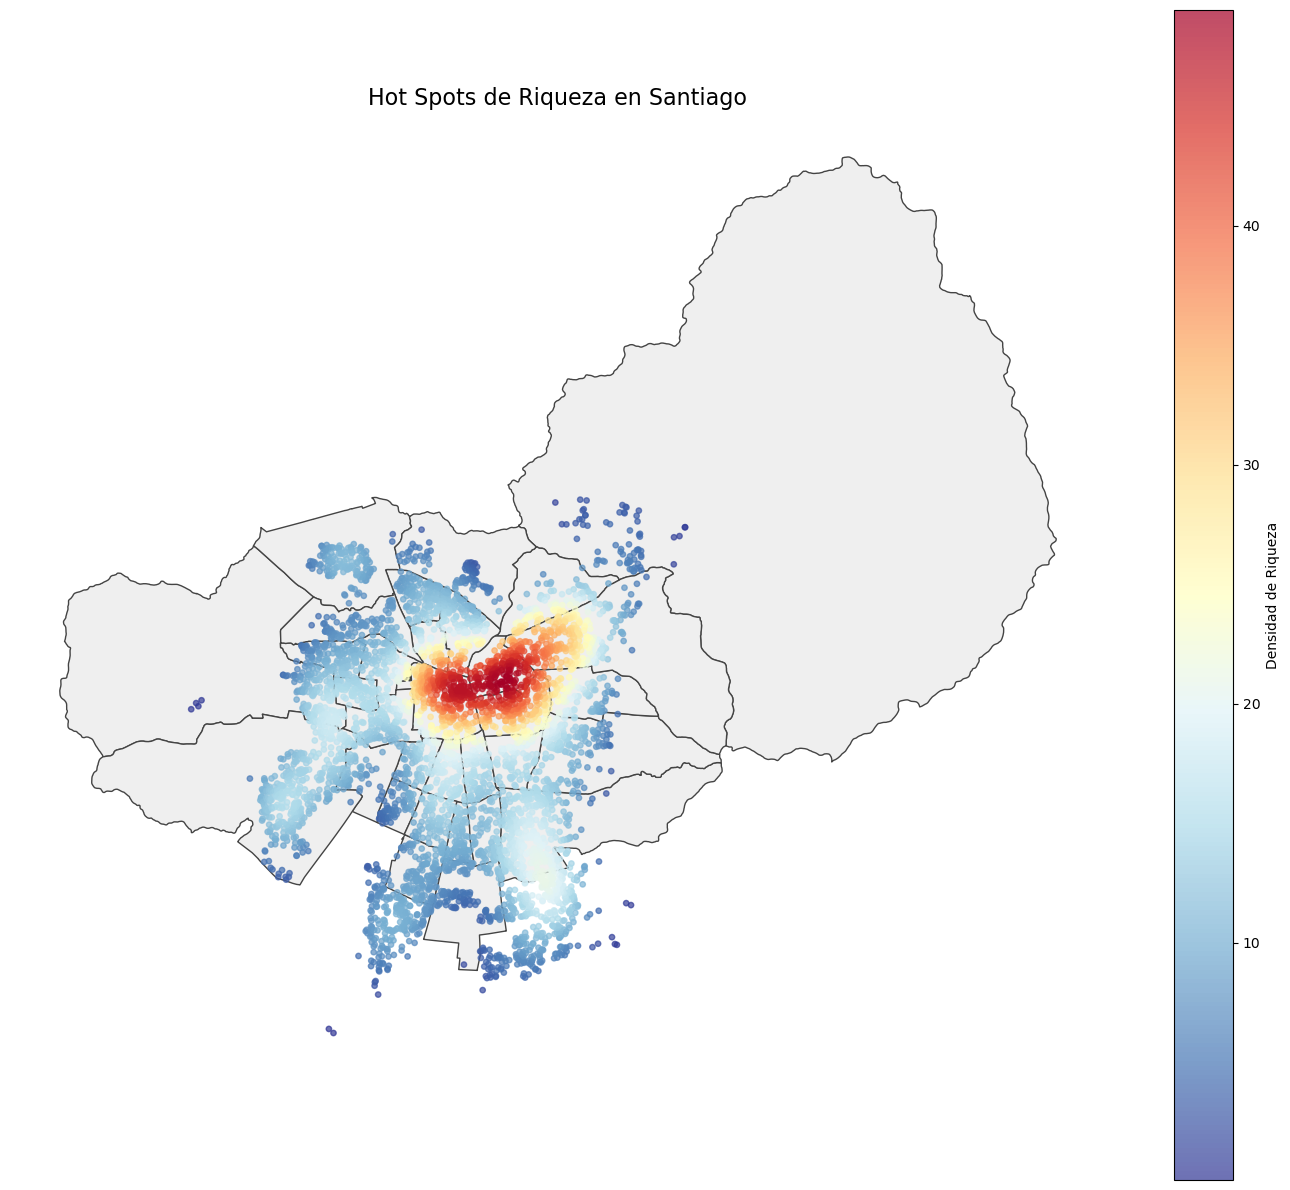

In [14]:
# Crear un mapa de calor integrado que muestre los hot spots de riqueza
fig, ax = plt.subplots(figsize=(14, 12))

# Base layer
df_stgo_merged.plot(color='#EFEFEF', edgecolor='#444444', ax=ax)

# Heat map layer using KDE (Kernel Density Estimation)
x = df_barrio['longitud']
y = df_barrio['latitud']
weights = df_barrio['nse']

from scipy.stats import gaussian_kde
xy = np.vstack([x, y])
z = gaussian_kde(xy, weights=weights)(xy)

# Sort points by density for better visualization
idx = z.argsort()
x, y, z = x[idx], y[idx], z[idx]

scatter = ax.scatter(x, y, c=z, cmap='RdYlBu_r', s=15, alpha=0.7)
plt.colorbar(scatter, label='Densidad de Riqueza')
plt.title('Hot Spots de Riqueza en Santiago', fontsize=16)
plt.axis('off')
plt.tight_layout()
plt.show()

# Parte 7: Preguntas de Análisis

1. Análisis Sociourbano:

- ¿Es posible identificar sectores de concentración de riqueza en Santiago? ¿Qué comunas conforman estos sectores y qué características geoespaciales comparten?
- ¿Existe un patrón espacial claro en la distribución del nivel socioeconómico en Santiago? ¿Cómo se relaciona este patrón con la estructura urbana de la ciudad?
- Basándose en los resultados del clustering, ¿podría decirse que Santiago presenta segregación socioespacial? Justifique su respuesta con evidencia cuantitativa derivada de los análisis realizados.
- Si tuviera que dividir Santiago en exactamente 3 macrozonas socioeconómicas, ¿cuáles serían estas y qué características particulares tendría cada una?

2. Comparación de Algoritmos:

- ¿Qué diferencias fundamentales observa entre los resultados obtenidos con K-Means, Clustering Jerárquico, DBSCAN y GMM? ¿Cuál considera más adecuado para este análisis socioespacial y por qué?
- Analice críticamente las ventajas y limitaciones de cada algoritmo de clustering en el contexto específico de datos georreferenciados con componente socioeconómica.
- ¿Qué algoritmo logra mejor capturar la heterogeneidad interna de las comunas? Proporcione evidencia cuantitativa que respalde su respuesta.

3. Interpretación Estadística:

- Para cada algoritmo, identifique los clusters con mayor y menor varianza interna de NSE. ¿Qué interpretación sociológica podría darse a estos resultados?
- Calcule y analice la correlación espacial (autocorrelación) del NSE utilizando el índice de Moran. ¿Qué nos dice esto sobre la estructura socio-urbana de Santiago?
- ¿Cómo se relacionan los resultados de los algoritmos de clustering con la varianza explicada en el análisis de componentes principales?

4. Aplicaciones y Extensiones:

- Proponga una aplicación práctica de los resultados obtenidos en el ámbito de políticas públicas urbanas o planificación territorial.
- Si tuviera acceso a datos temporales del NSE para Santiago (por ejemplo, para los últimos 20 años), ¿qué análisis adicionales realizaría para estudiar la evolución de la segregación urbana?
- ¿Cómo podría incorporar información adicional (criminalidad, densidad poblacional, acceso a servicios, etc.) para enriquecer este análisis? Describa metodológicamente cómo lo haría.